# Revenue and orders notebook

This report uses sample results from three sales regions. Monthly
revenue is $R_m = \sum_r R_{m,r}$.

In [1]:
import altair as alt
import numpy as np
import plotly.graph_objects as go
from altair.utils.mimebundle import spec_to_mimebundle
from IPython.display import display

In [2]:
chart = go.Figure(go.Bar(
    x=["Jan", "Feb", "Mar"],
    y=np.array([3, 12, 7], dtype=np.int32),
    name="Revenue", marker_color="#176c68",
))
chart.update_layout(title="Monthly revenue", xaxis_title="Month", yaxis_title="Revenue")
chart.show(renderer="plotly_mimetype")

In [3]:
chart = go.Figure(go.Scatter(
    x=np.array([1, 3, 10], dtype=np.float64),
    y=np.array([4, 9, 5], dtype=np.float64),
    mode="markers", name="Observations", marker_color="#9b3d00",
))
chart.update_layout(title="Revenue observations", xaxis_title="Sample", yaxis_title="Revenue")
chart.show(renderer="plotly_mimetype")

In [4]:
monthly_revenue = [
    {"month": "Jan", "revenue": 3},
    {"month": "Feb", "revenue": 12},
    {"month": "Mar", "revenue": 7},
]
chart = alt.Chart(alt.NamedData(name="monthly_revenue")).mark_bar(color="#254fb5").encode(
    x=alt.X("month:N", title="Month", sort=["Jan", "Feb", "Mar"]),
    y=alt.Y("revenue:Q", title="Revenue"),
).properties(title="Revenue by month", width=490, height=240,
             datasets={"monthly_revenue": monthly_revenue})
display(spec_to_mimebundle(chart.to_dict(), "vega-lite", mode="vega-lite", vegalite_version="6.4"), raw=True)

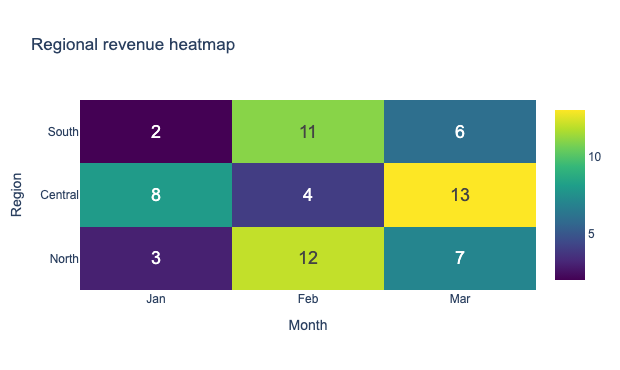

In [5]:
chart = go.Figure(go.Heatmap(
    x=["Jan", "Feb", "Mar"], y=["North", "Central", "South"],
    z=[[3, 12, 7], [8, 4, 13], [2, 11, 6]], colorscale="Viridis",
    texttemplate="%{z}", textfont={"size": 18},
))
chart.update_layout(
    title="Regional revenue heatmap", xaxis_title="Month", yaxis_title="Region",
    width=620, height=370, font={"family": "Arial"},
)
chart.show(renderer="plotly_mimetype+png")

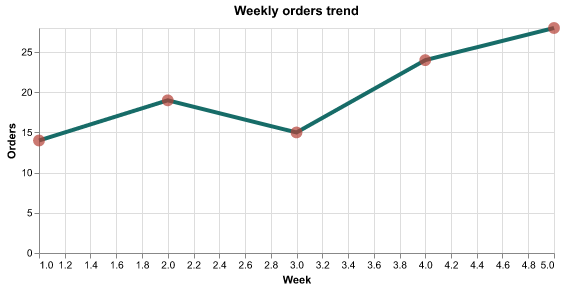

In [6]:
chart_data = alt.Data(values=[
    {"week": 1, "orders": 14}, {"week": 2, "orders": 19},
    {"week": 3, "orders": 15}, {"week": 4, "orders": 24},
    {"week": 5, "orders": 28},
])
base = alt.Chart(chart_data).encode(
    x=alt.X("week:Q", title="Week", scale=alt.Scale(zero=False)),
    y=alt.Y("orders:Q", title="Orders"),
)
chart = (base.mark_line(strokeWidth=4, color="#176c68")
         + base.mark_point(filled=True, size=140, color="#b54036")).properties(
    title="Weekly orders trend", width=515, height=225,
)
display(spec_to_mimebundle(chart.to_dict(), "vega-lite", mode="vega-lite", vegalite_version="6.4"), raw=True)

In [7]:
from IPython.display import HTML
display(HTML("<table><thead><tr><th>Region</th><th>Revenue</th></tr></thead>"
             "<tbody><tr><td>North</td><td>22</td></tr>"
             "<tr><td>Central</td><td>25</td></tr>"
             "<tr><td>South</td><td>19</td></tr></tbody></table>"))

Region,Revenue
North,22
Central,25
South,19
